# 🍔 QuickBite — Know Your Diners

**Brief from management:** *"Who are our diners? What do they order together? Who's about to stop ordering?"*

| Task | Method | Question it answers |
|---|---|---|
| 1 | K-Means clustering | Who are our diners? |
| 2 | Apriori association rules | What do they order together? |
| 3 | Classification | Who will come back? |
| 4 | `food_models.joblib` → `app.py` | Can a manager use it? |

Keep this notebook in the same folder as `diners.csv`, `orders.csv` and `app.py`. Running it top to bottom writes `food_models.joblib`, then `streamlit run app.py` starts the dashboard.

In [1]:
# pip install pandas numpy matplotlib seaborn scikit-learn mlxtend streamlit joblib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_auc_score, recall_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
SEED = 42

## 0. Load and explore the data

In [2]:
diners = pd.read_csv("diners.csv")
orders = pd.read_csv("orders.csv")

print("diners:", diners.shape, "| orders (item rows):", orders.shape)
print("baskets (orders):", orders["order_id"].nunique(), "| diners with orders:", orders["diner_id"].nunique())
print("missing values:", diners.isna().sum().sum() + orders.isna().sum().sum())
print("duplicate item rows within an order:", orders.duplicated(["order_id", "item"]).sum())
diners.head()

diners: (480, 9) | orders (item rows): (4924, 3)
baskets (orders): 1980 | diners with orders: 480
missing values: 0
duplicate item rows within an order: 0


,diner_id,age,orders_per_month,avg_order_value,avg_items_per_order,days_since_last_order,discount_rate,total_spend,reordered
0,D1293,36,3,156.82,7,26,0.27,504.96,0
1,D1283,37,3,164.51,7,24,0.16,439.86,0
2,D1034,24,16,44.68,2,0,0.73,676.57,1
3,D1380,36,9,99.45,3,9,0.13,866.99,1
4,D1430,34,8,88.04,4,11,0.10,728.98,1


In [3]:
diners.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,480.0,30.68,8.65,9.00,23.00,31.00,38.00,52.00
orders_per_month,480.0,9.04,4.45,1.00,5.00,9.00,12.00,20.00
avg_order_value,480.0,98.08,57.16,29.50,43.70,90.58,157.22,218.66
avg_items_per_order,480.0,3.51,1.87,1.00,2.00,3.00,5.00,9.00
days_since_last_order,480.0,10.81,7.12,0.00,5.00,9.00,15.00,34.00
discount_rate,480.0,0.38,0.23,0.00,0.16,0.36,0.60,0.86
total_spend,480.0,664.76,222.82,134.04,510.54,638.92,789.31,1490.17
reordered,480.0,0.60,0.49,0.00,0.00,1.00,1.00,1.00


In [4]:
print("Class balance of the target 'reordered':")
print(diners["reordered"].value_counts().rename({1: "1 = reordered (retained)", 0: "0 = churned"}))
print(f"\nMajority-class baseline accuracy = {diners['reordered'].mean():.0%} (always guess 'reorders')")

# Data-quality check
young = diners[diners["age"] < 18]
print(f"\nData-quality flag: {len(young)} diners are under 18 (youngest: {young['age'].min()}).")

Class balance of the target 'reordered':
reordered
1 = reordered (retained)    288
0 = churned                 192
Name: count, dtype: int64

Majority-class baseline accuracy = 60% (always guess 'reorders')

Data-quality flag: 20 diners are under 18 (youngest: 9).


**What we see**
- 480 diners, 1,980 orders, 17 menu items. No missing values and no duplicate items inside an order.
- The target is **60 / 40** (retained / churned), so any classifier must beat **60 %** — the score you'd get by always guessing "reorders".
- 20 diners are listed as under 18, one of them aged 9. That looks like an entry error (or a parent's account used by a child). Age isn't a clustering feature, so it doesn't affect the segments; I keep these rows but flag them for the data team.

---
## Task 1 — Segment the diners (K-Means clustering)

We cluster on the five **behaviour** features, in the exact order the dashboard expects. They sit on very different scales (orders per month ≈ 1–20, order value ≈ AED 30–220, discount rate 0–1), so we **standardise** them first. Otherwise K-Means, which measures distance, would be driven almost entirely by order value.

In [5]:
FEATURES = ["orders_per_month", "avg_order_value", "avg_items_per_order",
            "days_since_last_order", "discount_rate"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(diners[FEATURES])

ks = range(2, 11)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_))

k_table = pd.DataFrame({"k": list(ks), "inertia (WCSS)": np.round(inertia, 1),
                        "silhouette": np.round(silhouette, 3)})
k_table

,k,inertia (WCSS),silhouette
0,2,971.1,0.527
1,3,444.7,0.571
2,4,360.8,0.517
3,5,318.3,0.362
4,6,292.0,0.274
5,7,271.0,0.271
6,8,252.3,0.246
7,9,237.4,0.238
8,10,225.3,0.230


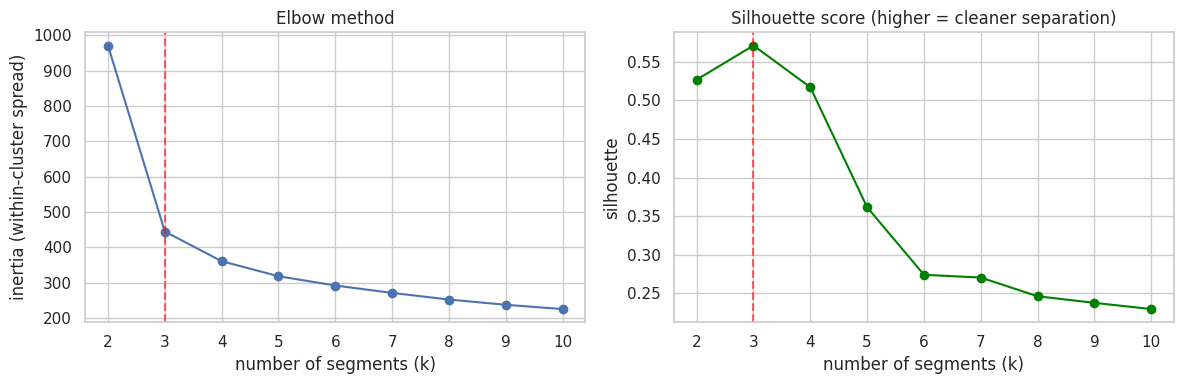

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertia, "o-")
ax[0].axvline(3, ls="--", c="red", alpha=.6)
ax[0].set(title="Elbow method", xlabel="number of segments (k)", ylabel="inertia (within-cluster spread)")
ax[1].plot(list(ks), silhouette, "o-", c="green")
ax[1].axvline(3, ls="--", c="red", alpha=.6)
ax[1].set(title="Silhouette score (higher = cleaner separation)", xlabel="number of segments (k)", ylabel="silhouette")
plt.tight_layout(); plt.show()

**Choosing k = 3**
- **Elbow:** inertia falls steeply from k = 2 → 3 (971 → 445, a 54 % drop), then flattens (3 → 4 only drops a further 19 %). The bend is at **k = 3**.
- **Silhouette:** peaks at **k = 3 (0.571)** and falls quickly after k = 4. Above 0.5 means the segments are clearly separated, not arbitrary slices.

Both methods agree, so we use **3 segments**.

In [7]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_scaled)
diners["cluster"] = kmeans.labels_

profile = (diners.groupby("cluster")[FEATURES + ["age", "total_spend", "reordered"]]
           .mean().round(2))
profile.insert(0, "diners", diners["cluster"].value_counts().sort_index())
profile

,diners,orders_per_month,avg_order_value,avg_items_per_order,days_since_last_order,discount_rate,age,total_spend,reordered
cluster,,,,,,,,,
0,150,3.63,173.91,5.98,18.13,0.31,40.23,625.40,0.15
1,200,13.10,42.13,1.99,5.00,0.62,22.33,554.46,0.98
2,130,9.02,96.67,2.98,11.30,0.10,32.51,879.88,0.52


**Naming the segments.** Rather than hard-coding "cluster 0 = families" (cluster numbers can shuffle if K-Means is re-run on another machine), the names are assigned by rule from each cluster's profile:
- the cluster with the **highest discount use** → *Budget Students*
- the cluster with the **biggest baskets** → *Family Feasters*
- the remaining one → *Premium Foodies*

In [8]:
c_student = profile["discount_rate"].idxmax()
c_family  = profile["avg_items_per_order"].idxmax()
c_premium = [c for c in profile.index if c not in (c_student, c_family)][0]
assert len({c_student, c_family, c_premium}) == 3, "naming rule clashed — check the profile table"

segment_names = {int(c_student): "Budget Students",
                 int(c_family):  "Family Feasters",
                 int(c_premium): "Premium Foodies"}
diners["segment"] = diners["cluster"].map(segment_names)
print(segment_names)

seg_profile = profile.rename(index=segment_names)
seg_profile

{1: 'Budget Students', 0: 'Family Feasters', 2: 'Premium Foodies'}


,diners,orders_per_month,avg_order_value,avg_items_per_order,days_since_last_order,discount_rate,age,total_spend,reordered
cluster,,,,,,,,,
Family Feasters,150,3.63,173.91,5.98,18.13,0.31,40.23,625.40,0.15
Budget Students,200,13.10,42.13,1.99,5.00,0.62,22.33,554.46,0.98
Premium Foodies,130,9.02,96.67,2.98,11.30,0.10,32.51,879.88,0.52


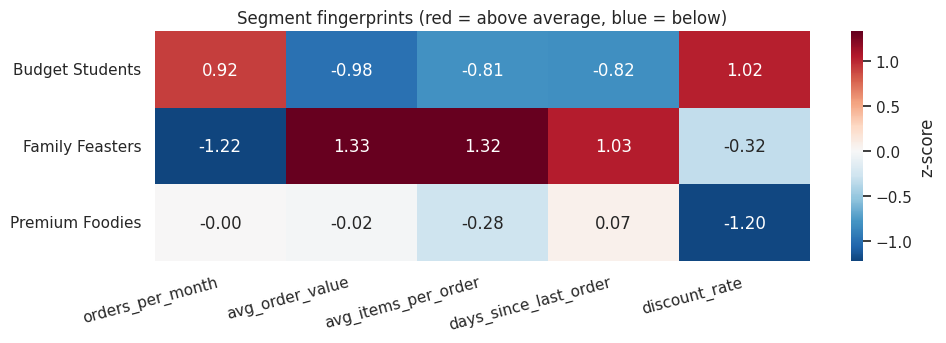

In [9]:
# Visual profile: how far each segment sits above/below the average diner (z-scores)
z = pd.DataFrame(X_scaled, columns=FEATURES).assign(segment=diners["segment"]).groupby("segment").mean()
plt.figure(figsize=(10, 3.6))
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score"})
plt.title("Segment fingerprints (red = above average, blue = below)")
plt.xticks(rotation=15, ha="right"); plt.yticks(rotation=0)
plt.ylabel(""); plt.tight_layout(); plt.show()

In [10]:
# What each segment actually orders (share of its order lines)
orders_seg = orders.merge(diners[["diner_id", "segment"]], on="diner_id")
item_share = (orders_seg.groupby("segment")["item"].value_counts(normalize=True)
              .mul(100).round(1).rename("% of lines").reset_index())
for seg, g in item_share.groupby("segment"):
    print(f"{seg:16s}", ", ".join(f"{r['item']} {r['% of lines']}%" for _, r in g.head(6).iterrows()))

Budget Students  cola 39.9%, fries 30.9%, burger 19.0%, wrap 10.2%
Family Feasters  dessert 23.8%, pizza 15.7%, biryani 15.6%, raita 15.6%, pasta 8.9%, salad 7.4%
Premium Foodies  salad 24.5%, sushi 16.5%, coffee 15.5%, wine 9.8%, steak 8.9%, green_tea 8.7%


### Segment profiles

| Segment | Size | Behaviour | What they order | Reorder rate |
|---|---|---|---|---|
| **Budget Students** | 200 (42 %) | Youngest (≈22). Order **very often** (≈13×/month) and **recently** (≈5 days), but small, cheap baskets (≈2 items, ≈AED 42). Use a discount on **62 %** of orders. | Cola, fries, burger, wrap — fast food only | **98 %** — very loyal |
| **Family Feasters** | 150 (31 %) | Oldest (≈40). Order **rarely** (≈4×/month) but **big** (≈6 items, ≈AED 174 per order — the highest ticket). Last order ≈18 days ago. | Biryani + raita, pizza, pasta, garlic bread, dessert — sharing food | **15 %** — mostly lapsing |
| **Premium Foodies** | 130 (27 %) | ≈32 years old. Regular (≈9×/month), mid-sized baskets (≈3 items, ≈AED 97) and almost **never use discounts** (10 %). Highest lifetime spend (≈AED 880). | Salad, sushi, miso soup, green tea, steak, wine, coffee — upscale items | **52 %** — a coin flip |

"Premium" here means what they buy and the fact that they pay full price, not the size of a single order (families spend more per order).

---
## Task 2 — What's ordered together (Apriori)

Each `order_id` is one basket. Apriori needs a one-hot table: one row per basket, one True/False column per item.

How to read a rule **A → B**:
- **support**: share of all baskets that contain A *and* B (how common the combo is)
- **confidence**: of baskets with A, the share that also contain B (how reliable the rule is)
- **lift**: confidence ÷ how common B is anyway. **Lift > 1** means A and B are bought together more often than chance; lift = 1 means no real link.

In [11]:
def one_hot_baskets(order_lines: pd.DataFrame) -> pd.DataFrame:
    baskets = order_lines.groupby("order_id")["item"].apply(list).tolist()
    te = TransactionEncoder()
    return pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)


def mine_rules(order_lines, min_support, min_confidence=0.5):
    basket = one_hot_baskets(order_lines)
    freq = apriori(basket, min_support=min_support, use_colnames=True)
    try:   # newer mlxtend versions accept/require num_itemsets
        rules = association_rules(freq, num_itemsets=len(basket), metric="lift", min_threshold=1.0)
    except TypeError:   # older mlxtend
        rules = association_rules(freq, metric="lift", min_threshold=1.0)
    rules = rules[rules["confidence"] >= min_confidence].copy()
    rules["if_bought"] = rules["antecedents"].apply(lambda s: " + ".join(sorted(s)))
    rules["then_also"] = rules["consequents"].apply(lambda s: " + ".join(sorted(s)))
    rules["itemset"] = rules.apply(lambda r: frozenset(r["antecedents"] | r["consequents"]), axis=1)
    rules["lift"] = rules["lift"].round(3)   # so mirrored rules (A→B, B→A) tie exactly and confidence breaks the tie
    rules = rules.sort_values(["lift", "confidence", "support"], ascending=False)
    return basket, rules


def top_rules(rules, n=10):
    """A→B and B→A share the same lift; keep only the more confident direction of each combo."""
    best = rules.drop_duplicates(subset="itemset", keep="first")   # already sorted by lift, confidence
    return best[["if_bought", "then_also", "support", "confidence", "lift"]].head(n).round(3).reset_index(drop=True)

In [12]:
basket_all, rules_all = mine_rules(orders, min_support=0.02, min_confidence=0.5)
print(f"{len(basket_all)} baskets × {basket_all.shape[1]} items  →  {len(rules_all)} rules with lift > 1 and confidence ≥ 0.5")
overall_top = top_rules(rules_all, 12)
overall_top.index += 1
overall_top

1980 baskets × 17 items  →  59 rules with lift > 1 and confidence ≥ 0.5


,if_bought,then_also,support,confidence,lift
1,cola + dessert,garlic_bread,0.021,0.933,30.800
2,cola + pizza,garlic_bread,0.021,0.933,30.800
3,miso_soup + sushi,green_tea,0.055,0.915,13.834
4,miso_soup,green_tea,0.060,0.915,13.826
5,biryani + salad,raita,0.026,0.945,13.765
6,dessert + pasta,pizza,0.033,0.943,13.627
7,dessert + raita,biryani,0.029,0.919,13.385
8,biryani,raita,0.062,0.897,13.060
9,salad + steak,wine,0.060,0.967,13.028
10,steak,wine,0.064,0.948,12.766


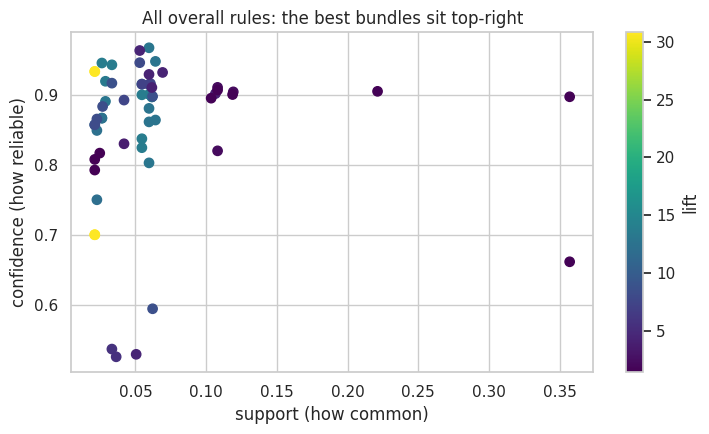

In [13]:
plt.figure(figsize=(7.5, 4.5))
plt.scatter(rules_all["support"], rules_all["confidence"], c=rules_all["lift"], cmap="viridis", s=45)
plt.colorbar(label="lift")
plt.xlabel("support (how common)"); plt.ylabel("confidence (how reliable)")
plt.title("All overall rules: the best bundles sit top-right")
plt.tight_layout(); plt.show()

**Interpreting the top overall rules**

1. **Cola + pizza (or cola + dessert) → garlic bread** — confidence 93 %, lift 30.8. Garlic bread almost never appears without this "pizza night" combo. It's the highest lift, but only ≈2 % of baskets, so it's a **niche, high-certainty add-on**: *show garlic bread whenever cola + pizza is in the cart.*
2. **Sushi + miso soup → green tea** — confidence 92 %, lift 13.8, in ≈5.5 % of baskets. Strong *and* reasonably common. → *Sell a "Japanese set" (sushi + miso + green tea) as one bundle.*
3. **Steak + salad → wine** — confidence 97 %, lift 13.0, ≈6 % of baskets. → *Offer a "steak dinner" pairing with wine.*
4. **Biryani ↔ raita** — 90 % confidence in **both** directions. These two are effectively one product. → *Default raita into every biryani order (or price them as a combo).*

**A caution about the overall lifts:** they're very high (13–31) partly because each segment eats from its own menu (only families buy biryani, only premium diners buy sushi). Some of the "togetherness" is really "the same kind of customer". The per-segment runs below remove that effect.

### Per-segment rules — do families order differently from students?

In [14]:
seg_rules = {}
for seg in ["Budget Students", "Family Feasters", "Premium Foodies"]:
    lines = orders_seg[orders_seg["segment"] == seg]
    b, r = mine_rules(lines, min_support=0.05, min_confidence=0.5)
    seg_rules[seg] = r
    print(f"\n=== {seg}: {len(b)} baskets, {len(r)} rules ===")
    display(top_rules(r, 6))


=== Budget Students: 1123 baskets, 5 rules ===


,if_bought,then_also,support,confidence,lift
0,wrap,cola + fries,0.191,0.820,1.302
1,wrap,fries,0.210,0.904,1.289
2,burger,cola,0.390,0.905,1.000



=== Family Feasters: 304 baskets, 51 rules ===


,if_bought,then_also,support,confidence,lift
0,cola + dessert + pizza,garlic_bread,0.115,0.946,4.793
1,cola + dessert,garlic_bread,0.138,0.933,4.729
2,cola + pizza,garlic_bread,0.138,0.933,4.729
3,cola,garlic_bread,0.161,0.925,4.684
4,pasta,dessert + pizza,0.217,0.857,2.118
5,biryani + salad,raita,0.171,0.945,2.113



=== Premium Foodies: 553 baskets, 27 rules ===


,if_bought,then_also,support,confidence,lift
0,miso_soup + sushi,green_tea,0.195,0.915,3.864
1,miso_soup,green_tea,0.213,0.915,3.861
2,salad + steak,wine,0.213,0.967,3.639
3,steak,wine,0.230,0.948,3.565
4,salad + sushi,coffee,0.190,0.946,2.236
5,pasta,coffee,0.181,0.893,2.110


In [15]:
# Why do students have so few strong rules? Look at how often each item appears in their baskets.
b_students = one_hot_baskets(orders_seg[orders_seg["segment"] == "Budget Students"])
print("Share of student baskets containing each item:")
for item, share in b_students.mean().sort_values(ascending=False).items():
    print(f"  {item:8s} {share:.1%}")

Share of student baskets containing each item:
  cola     90.5%
  fries    70.2%
  burger   43.1%
  wrap     23.2%


**Per-segment interpretation**

| Segment | Best rule | Business reading |
|---|---|---|
| **Family Feasters** | cola + dessert + pizza → garlic bread (conf ≈95 %, lift ≈4.8); biryani + salad → raita (conf ≈95 %, lift ≈2.1) | Two distinct "feast" baskets: a **pizza night** (pizza, cola, dessert, garlic bread, often pasta) and an **Indian meal** (biryani, raita, salad). → Sell both as family meal deals. |
| **Premium Foodies** | sushi + miso soup → green tea (conf ≈92 %, lift ≈3.9); steak + salad → wine (conf ≈97 %, lift ≈3.6) | Two set menus: **Japanese** and **steak dinner**. → Curated "chef's set" bundles; no discount needed. |
| **Budget Students** | wrap → fries (conf ≈90 %, lift only ≈1.3); burger → cola has lift **1.0** | Cola is in ≈90 % of student baskets, so it's a default, not a cross-sell. Their menu is just burger-or-wrap + fries + cola. → The lever is a **fixed-price combo meal**, not new items. |

**Yes, the segments order very differently.** Families and premium diners have clear, promotable bundles (within-segment lift 2–4.8). Students have almost no associations beyond lift ≈1, because nearly every basket is the same.

Notice how the lifts shrink inside a segment: biryani + salad → raita has lift 13.8 overall but only 2.1 among families. That confirms the caution above. The overall number mixes "these items go together" with "only families buy these items". The per-segment lift is the honest measure of a bundle.

---
## Task 3 — Predict who reorders (classification)

The dashboard sends **seven** inputs: the five clustering features plus `age` and `total_spend`. Target: `reordered` (1 = retained, 0 = churned).

I hold back 25 % of diners as an untouched test set (stratified so it keeps the 60/40 split). Models are compared with 5-fold cross-validation on the training set only.

In [16]:
CLF_FEATURES = FEATURES + ["age", "total_spend"]
X = diners[CLF_FEATURES]
y = diners["reordered"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)

baseline_acc = max(y_test.mean(), 1 - y_test.mean())
print(f"train: {len(X_train)}  test: {len(X_test)}")
print(f"Baseline (always predict 'reorders') test accuracy: {baseline_acc:.1%}")

train: 360  test: 120
Baseline (always predict 'reorders') test accuracy: 60.0%


In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = {
    "Logistic Regression":            make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Logistic Regression (balanced)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Decision Tree (depth 4)":        DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest":                  RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED),
    "Gradient Boosting":              GradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, model in candidates.items():
    pred = cross_val_predict(model, X_train, y_train, cv=cv)
    proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    rows.append({"model": name,
                 "CV accuracy": accuracy_score(y_train, pred),
                 "CV ROC-AUC": roc_auc_score(y_train, proba),
                 "churners caught (recall of 0)": recall_score(y_train, pred, pos_label=0)})
cv_table = pd.DataFrame(rows).set_index("model").round(3).sort_values("CV ROC-AUC", ascending=False)
cv_table

,CV accuracy,CV ROC-AUC,churners caught (recall of 0)
model,,,
Logistic Regression,0.861,0.936,0.861
Logistic Regression (balanced),0.850,0.935,0.910
Random Forest,0.856,0.929,0.868
Gradient Boosting,0.842,0.924,0.819
Decision Tree (depth 4),0.833,0.882,0.840


### Which mistake costs QuickBite more?

There are two kinds of error:
- **False alarm:** a loyal diner is flagged "at risk" → we send them a voucher they didn't need. Cost: one discount.
- **Missed churner:** a diner who is about to leave is predicted "will reorder" → we do nothing and lose them. Cost: all their future orders (for a family that's ≈AED 174 per order).

**Missing a churner is much more expensive.** So among models that are equally accurate, we prefer the one that **catches more churners**.

**Choice: Logistic Regression with `class_weight="balanced"`.** Logistic regression is at the top on ROC-AUC (≈0.94) and accuracy, and is easy to explain. The balanced version gives slightly more weight to the minority (churn) class. It gives up about one point of accuracy in exchange for catching **≈91 % of churners instead of ≈86 %**. That's the right trade given the cost asymmetry. Because `class_weight` is built into the model, the dashboard's `clf.predict()` automatically uses this cost-aware behaviour.

In [18]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"Model test accuracy : {test_acc:.1%}")
print(f"Baseline accuracy   : {baseline_acc:.1%}")
print(f"Improvement         : +{(test_acc - baseline_acc)*100:.1f} percentage points")
print(f"Test ROC-AUC        : {roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["churned (0)", "reordered (1)"]))

Model test accuracy : 85.8%
Baseline accuracy   : 60.0%
Improvement         : +25.8 percentage points
Test ROC-AUC        : 0.960

               precision    recall  f1-score   support

  churned (0)       0.77      0.92      0.84        48
reordered (1)       0.94      0.82      0.87        72

     accuracy                           0.86       120
    macro avg       0.85      0.87      0.86       120
 weighted avg       0.87      0.86      0.86       120



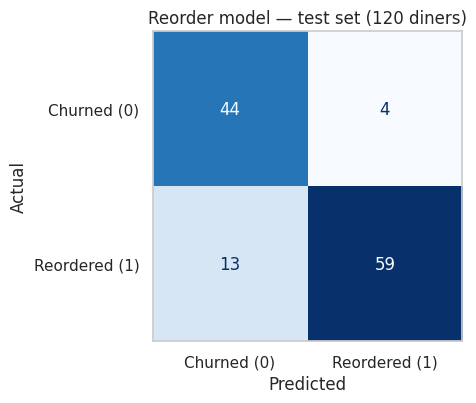

Churners correctly flagged as at risk : 44 of 48  (92%)
Churners MISSED (predicted to reorder): 4   ← the expensive error
Loyal diners wrongly flagged at risk  : 13   ← the cheap error (a wasted voucher)
Loyal diners correctly predicted      : 59 of 72


In [19]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["Churned (0)", "Reordered (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False)
ax.set(title="Reorder model — test set (120 diners)", xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Churners correctly flagged as at risk : {tn} of {tn+fp}  ({tn/(tn+fp):.0%})")
print(f"Churners MISSED (predicted to reorder): {fp}   ← the expensive error")
print(f"Loyal diners wrongly flagged at risk  : {fn}   ← the cheap error (a wasted voucher)")
print(f"Loyal diners correctly predicted      : {tp} of {tp+fn}")

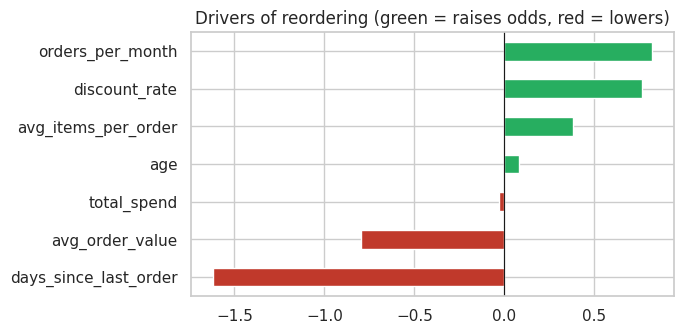

,diners,actual_reorder_rate,predicted_reorder_rate,missed_churners,false_alarms
segment,,,,,
Budget Students,49,0.98,1.00,1,0
Family Feasters,38,0.08,0.05,0,1
Premium Foodies,33,0.64,0.36,3,12


In [20]:
# What drives the prediction? (standardised logistic-regression coefficients)
coefs = pd.Series(clf[-1].coef_[0], index=CLF_FEATURES).sort_values()
coefs.plot.barh(figsize=(7, 3.5), color=["#c0392b" if v < 0 else "#27ae60" for v in coefs])
plt.title("Drivers of reordering (green = raises odds, red = lowers)")
plt.axvline(0, c="k", lw=.8); plt.tight_layout(); plt.show()

# Reorder rate the model predicts vs. actual, by segment (test set)
chk = X_test.assign(actual=y_test, predicted=y_pred, segment=diners.loc[X_test.index, "segment"])
chk["missed churner"] = (chk["actual"] == 0) & (chk["predicted"] == 1)
chk["false alarm"]    = (chk["actual"] == 1) & (chk["predicted"] == 0)
chk.groupby("segment").agg(diners=("actual", "size"), actual_reorder_rate=("actual", "mean"),
                           predicted_reorder_rate=("predicted", "mean"),
                           missed_churners=("missed churner", "sum"), false_alarms=("false alarm", "sum")).round(2)

**Reading the result**
- The model scores about **86 % accuracy against a 60 % baseline**, roughly 26 points better than guessing, with ROC-AUC ≈0.96.
- **Its errors lean the cheap way, as intended.** On the test set it catches **44 of 48 churners**. It misses only 4. Its other errors are 13 loyal diners flagged "at risk", which costs QuickBite a voucher, not a customer.
- **Where the errors happen:** 15 of the 17 test errors are in **Premium Foodies**, the coin-flip segment. Students (almost all stay) and families (almost all leave) are easy calls. Among premium diners the model leans cautious and flags some who would have stayed, which is the direction we asked for.
- **Strongest signals:** a long gap since the last order (recency) is the biggest churn warning. Ordering often and using discounts both point to staying; high order values point to leaving, which fits the infrequent, big-basket family pattern.

---
## Task 4 — Save the models for the dashboard

`reco` maps each segment name to its five most-ordered items (ranked by how many of that segment's baskets contain the item).

In [21]:
reco = {}
for seg in segment_names.values():
    b = one_hot_baskets(orders_seg[orders_seg["segment"] == seg])
    reco[seg] = b.mean().sort_values(ascending=False).head(5).index.tolist()
reco

{'Budget Students': ['cola', 'fries', 'burger', 'wrap'],
 'Family Feasters': ['dessert', 'pizza', 'raita', 'biryani', 'pasta'],
 'Premium Foodies': ['salad', 'sushi', 'coffee', 'wine', 'steak']}

In [22]:
bundle = {
    "scaler":        scaler,
    "kmeans":        kmeans,
    "segment_names": segment_names,
    "clf":           clf,
    "features":      FEATURES,
    "reco":          reco,
}
joblib.dump(bundle, "food_models.joblib")
print("Saved food_models.joblib with keys:", list(bundle))

Saved food_models.joblib with keys: ['scaler', 'kmeans', 'segment_names', 'clf', 'features', 'reco']


### Test it exactly the way `app.py` will call it

In [23]:
M = joblib.load("food_models.joblib")

def analyse(profile: dict):
    # copied logic from app.py
    row = pd.DataFrame([profile])
    seg = int(M["kmeans"].predict(M["scaler"].transform(row[M["features"]]))[0])
    name = M["segment_names"].get(seg, f"Segment {seg}")
    cols = M["features"] + ["age", "total_spend"]
    reorder = int(M["clf"].predict(row[cols])[0])
    prob = float(M["clf"].predict_proba(row[cols])[0][1])
    return name, reorder, prob, M["reco"].get(name, [])

test_profiles = {
    "Uni student, orders daily-ish":  dict(age=21, orders_per_month=15, avg_order_value=40,  avg_items_per_order=2, days_since_last_order=3,  discount_rate=0.70, total_spend=600),
    "Parent, big weekend orders":     dict(age=42, orders_per_month=3,  avg_order_value=180, avg_items_per_order=6, days_since_last_order=20, discount_rate=0.30, total_spend=550),
    "Professional, sushi regular":    dict(age=31, orders_per_month=10, avg_order_value=95,  avg_items_per_order=3, days_since_last_order=6,  discount_rate=0.05, total_spend=950),
    "Professional, gone quiet":       dict(age=34, orders_per_month=8,  avg_order_value=110, avg_items_per_order=3, days_since_last_order=21, discount_rate=0.05, total_spend=880),
    "Dashboard default profile":      dict(age=28, orders_per_month=8,  avg_order_value=90,  avg_items_per_order=3, days_since_last_order=10, discount_rate=0.30, total_spend=800),
}
out = []
for label, p in test_profiles.items():
    name, r, prob, items = analyse(p)
    out.append({"diner": label, "segment": name, "will reorder?": "Yes" if r else "At risk",
                "reorder prob": f"{prob:.0%}", "recommended": " · ".join(items)})
pd.DataFrame(out).set_index("diner")

,segment,will reorder?,reorder prob,recommended
diner,,,,
"Uni student, orders daily-ish",Budget Students,Yes,99%,cola · fries · burger · wrap
"Parent, big weekend orders",Family Feasters,At risk,4%,dessert · pizza · raita · biryani · pasta
"Professional, sushi regular",Premium Foodies,Yes,70%,salad · sushi · coffee · wine · steak
"Professional, gone quiet",Premium Foodies,At risk,4%,salad · sushi · coffee · wine · steak
Dashboard default profile,Premium Foodies,Yes,61%,salad · sushi · coffee · wine · steak


The output matches the business logic. The student is safe. The family diner is in the at-risk segment and gets flagged. The two professionals land in the same segment, but the model separates the active one (likely to reorder) from the one who has **gone quiet for three weeks** (at risk). That kind of early warning is what the retention team needs.

**Run the dashboard** (from this folder, in a terminal):
```
streamlit run app.py
```

---
## Business takeaway

In [24]:
# Size of the prize: monthly order value (orders/month × AED per order) held by diners who churned
diners["monthly_value"] = diners["orders_per_month"] * diners["avg_order_value"]
prize = diners.groupby("segment").agg(
    diners=("diner_id", "size"),
    reorder_rate=("reordered", "mean"),
    monthly_value_per_diner=("monthly_value", "mean"),
    monthly_value_lost_to_churners=("monthly_value", lambda s: s[diners.loc[s.index, "reordered"] == 0].sum()),
).round(2)
prize

,diners,reorder_rate,monthly_value_per_diner,monthly_value_lost_to_churners
segment,,,,
Budget Students,200,0.98,551.10,1737.64
Family Feasters,150,0.15,630.28,79123.45
Premium Foodies,130,0.52,871.79,54888.87


> **Focus on Family Feasters.** They place the biggest orders (≈AED 174, ≈6 items) but **85 % have churned**, which leaves ≈AED 79k of monthly order value sitting with diners who've gone — the largest leak in the business. **Promote their own bundles as family meal deals:** the *pizza night* (pizza + cola + dessert → garlic bread, 93 % confidence) and *biryani + raita* (90 % both ways). For Premium Foodies, a coin-flip 52 % segment with the highest value per diner, use a *Japanese set* (sushi + miso + green tea) and a *steak + wine* pairing rather than discounts. **Use the reorder model as a weekly early-warning list:** score every diner, send win-back offers built on their segment's favourite items to anyone flagged "at risk". It catches ≈9 in 10 churners, and its false alarms only cost a voucher. Budget Students already reorder 98 % of the time while using discounts on 62 % of orders, so it's worth testing whether some of that discount spend can be pulled back.